# A propósito de un modelo de matemática aplicada

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cmorregof/taller-cd-ml-2026-2/blob/main/posts/a_proposito_de_un_modelo_de_matematica_aplicada.ipynb)

Carlos Manuel Orrego Franco · Taller en Ciencia de Datos y Aprendizaje Automático · Especialización en Estadística · Universidad Nacional de Colombia, Sede Manizales

En el taller resolvimos el dengue de Bucaramanga con aprendizaje automático. Este cuaderno toma el mismo dato y le pone al lado un modelo de otra tradición: tres ecuaciones diferenciales, un método numérico escrito a mano y una verosimilitud. Es el modelo SIR, y lo trabajo como lo hago con mis estudiantes de Métodos Numéricos, con Runge-Kutta de orden 4 y estimación por máxima verosimilitud.

Responde cuatro preguntas:

1. ¿Qué parámetros del SIR explican mejor la epidemia de 2024?
2. ¿Se puede estimar el número reproductivo $R_0$ con la curva de casos?
3. ¿Qué cambia si se trae de afuera un dato que la curva no tiene?
4. ¿Sirve el modelo para pronosticar, frente a los modelos del taller?

Corre completo en Colab en unos seis minutos: **Entorno de ejecución → Ejecutar todas**.

> **La fuente.** Las fichas de notificación de dengue de SIVIGILA las publica la Alcaldía de Bucaramanga en [datos.gov.co, conjunto `qzc7-jbg3`](https://www.datos.gov.co/d/qzc7-jbg3), con licencia CC BY-SA 4.0. Cada fila es un caso notificado por un médico.

In [1]:
# Celda de arranque. No hay que cambiarle nada: trae las herramientas del curso.
import pathlib, subprocess, sys
raiz = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path.cwd() / "taller-cd-ml-2026-2"] if (p / "taller" / "datos.py").exists()), None)
if raiz is None:
    subprocess.run(["git", "clone", "-q", "https://github.com/cmorregof/taller-cd-ml-2026-2.git"], check=True)
    raiz = pathlib.Path("taller-cd-ml-2026-2")
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from taller import descargar, procedencia

PALETA = ["#1D4E89", "#D7263D", "#1B998B", "#6C4AB6", "#5BC0EB", "#F49097", "#9AA5B1"]      # colores del curso
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=PALETA), "axes.titleweight": "bold", "figure.dpi": 110})
print("Herramientas listas.")

Herramientas listas.


## 1. El dato

Cada ficha trae la fecha de inicio de síntomas. Cuento los casos por semana epidemiológica, de domingo a sábado. Dejo por fuera las fichas de mortalidad, que registran otro evento, y las descartadas. La serie se corta en la semana del 10 de agosto de 2025, porque las semanas siguientes estaban incompletas cuando bajé el dato.

[dengue] Ya estaba descargado. Leo la copia de esta sesión.
Fichas: 28626 | de mortalidad: 16 | descartadas: 1 | quedan: 28610
Serie: 555 semanas, 28520 casos, de 2014-12-28 a 2025-08-10
2024: 52 semanas, 11437 casos (40 % del total), pico de 454 en la semana del 2024-06-16


/home/claude/taller-cd-ml-2026-2/taller/datos.py:139: DtypeWarning: Columns (0: clasfinal, 1: conducta) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(en_cache)


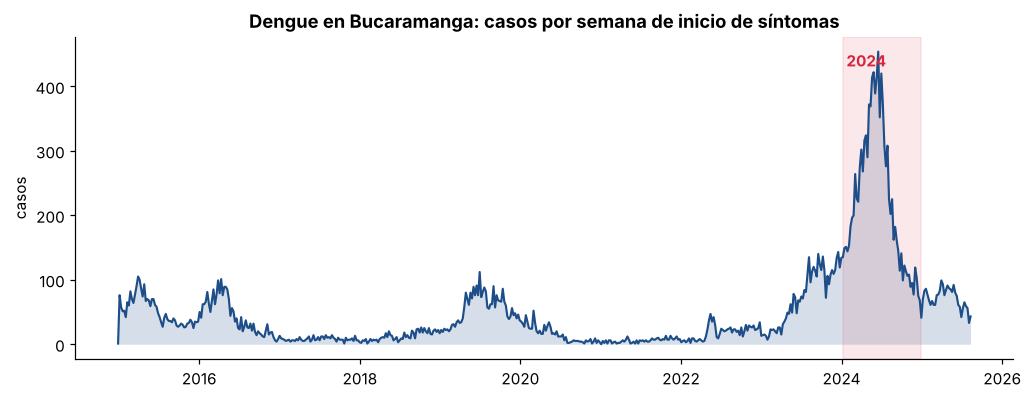

In [2]:
from taller.dengue import serie_semanal

serie = serie_semanal(avisar=True)
ola = serie["2024-01-07":"2024-12-29"]             # las 52 semanas epidemiológicas de 2024
y = ola.values.astype(float)
print(f"Serie: {len(serie)} semanas, {int(serie.sum())} casos, de {serie.index[0].date()} a {serie.index[-1].date()}")
print(f"2024: {len(ola)} semanas, {int(ola.sum())} casos ({ola.sum() / serie.sum() * 100:.0f} % del total), pico de {int(ola.max())} en la semana del {ola.idxmax().date()}")

fig, eje = plt.subplots(figsize=(11, 3.8))
eje.fill_between(serie.index, serie.values, color="#1D4E89", alpha=0.18, lw=0); eje.plot(serie.index, serie.values, color="#1D4E89", lw=1.4)
eje.axvspan(ola.index[0], ola.index[-1], color="#D7263D", alpha=0.10); eje.text(ola.index[0], serie.max(), " 2024", color="#D7263D", va="top", ha="left", weight="bold")
eje.set(title="Dengue en Bucaramanga: casos por semana de inicio de síntomas", ylabel="casos"); plt.show()

La epidemia de 2024 no se parece a nada de los nueve años anteriores. Me quedo con ese año, las 52 semanas sombreadas, para ajustar el modelo. La elección de la ventana es una decisión mía, y en la sección 6 mido cuánto pesa.

## 2. El modelo

El SIR divide una población de tamaño $N$ en susceptibles $S$, infectados $I$ y recuperados $R$. Con el tiempo $t$ en semanas,

$$S' = -\beta\,\frac{S\,I}{N},\qquad I' = \beta\,\frac{S\,I}{N}-\gamma\,I,\qquad R'=\gamma\,I.$$

$\beta$ es la tasa de contagio y $1/\gamma$ es lo que dura, en promedio, una infección. El **número reproductivo básico** es $R_0=\beta/\gamma$: a cuántos contagia un infectado cuando todos los demás son susceptibles. Al comienzo de una epidemia los casos crecen como $e^{rt}$, con **tasa de crecimiento** $r=\beta-\gamma$.

El dato no observa $I(t)$. Observa casos nuevos por semana, que en el modelo son los susceptibles que dejaron de serlo durante esa semana:

$$\mu_w = S(t_w)-S(t_w+1).$$

Dos advertencias antes de seguir. El dengue lo transmite un mosquito, y este modelo no tiene mosquitos: resume en $\beta$ y $\gamma$ todo el ciclo de persona a mosquito a persona. Y $N$ no es la población de Bucaramanga. Es la población **efectiva** del modelo, la gente que podía infectarse y además terminar en una ficha, y por eso es un parámetro que hay que estimar. La condición inicial es $S(0)=N-I_0$, $I(0)=I_0$.

### Resolverlo: Runge-Kutta de orden 4

El sistema no tiene solución en fórmula cerrada. Lo resuelvo con el método de RK4, que avanza un paso de tamaño $h$ con un promedio ponderado de cuatro pendientes:

$$k_1=f(t_i,w_i),\quad k_2=f\!\left(t_i+\tfrac h2,\,w_i+\tfrac h2k_1\right),\quad k_3=f\!\left(t_i+\tfrac h2,\,w_i+\tfrac h2k_2\right),\quad k_4=f(t_i+h,\,w_i+h\,k_3),$$

$$w_{i+1}=w_i+\tfrac h6\,(k_1+2k_2+2k_3+k_4).$$

La función es la del laboratorio de mi curso. La primera comprobación es la del libro de Burden: para $y'=y-t^2+1$, $y(0)=0{,}5$, con $h=0{,}2$ y diez pasos, RK4 debe dar $5{,}3053630$.

In [3]:
def rk4(f, t0, y0, h, n):
    """Runge-Kutta de orden 4 para y' = f(t, y), y(t0) = y0. Da n pasos de tamaño h."""
    t = t0 + h * np.arange(n + 1)
    w = np.zeros((n + 1, np.size(y0))); w[0] = y0
    for i in range(n):
        k1 = f(t[i], w[i])
        k2 = f(t[i] + h / 2, w[i] + h / 2 * k1)
        k3 = f(t[i] + h / 2, w[i] + h / 2 * k2)
        k4 = f(t[i] + h, w[i] + h * k3)
        w[i + 1] = w[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return t, w

burden = rk4(lambda t, y: y - t**2 + 1, 0.0, 0.5, 0.2, 10)[1][-1, 0]
print(f"RK4 sobre el problema de prueba de Burden: {burden:.7f} (el libro reporta 5.3053630)")

PASOS = 4                                    # pasos de RK4 por semana: h = 1/4 de semana

def sir(t, u, beta, gamma, N):
    S, I = u
    contagios = beta * S * I / N
    return np.array([-contagios, contagios - gamma * I])

def casos_con_rk4(beta, gamma, N, I0, semanas):
    """Casos nuevos por semana que predice el SIR: lo que baja S de una semana a la siguiente."""
    _, w = rk4(lambda t, u: sir(t, u, beta, gamma, N), 0.0, [N - I0, I0], 1 / PASOS, semanas * PASOS)
    S = w[::PASOS, 0]
    return S[:-1] - S[1:]

RK4 sobre el problema de prueba de Burden: 5.3053630 (el libro reporta 5.3053630)


Para estimar los parámetros voy a resolver el sistema decenas de miles de veces. Por eso escribo la misma fórmula una segunda vez, con números sueltos en lugar de arreglos, que en Python es unas diez veces más rápido. La celda comprueba que las dos versiones dan lo mismo, y que partir la semana en más pasos no cambia el resultado.

In [4]:
def casos_del_modelo(beta, gamma, N, I0, semanas, pasos=PASOS):
    """Lo mismo que casos_con_rk4, con la fórmula de RK4 escrita para dos números (S, I)."""
    h = 1.0 / pasos
    S, I = N - I0, I0
    def f(S, I):
        contagios = beta * S * I / N
        return -contagios, contagios - gamma * I
    salida = np.empty(semanas); S_antes = S
    for w in range(semanas):
        for _ in range(pasos):
            a1, b1 = f(S, I)
            a2, b2 = f(S + h / 2 * a1, I + h / 2 * b1)
            a3, b3 = f(S + h / 2 * a2, I + h / 2 * b2)
            a4, b4 = f(S + h * a3, I + h * b3)
            S += h / 6 * (a1 + 2 * a2 + 2 * a3 + a4); I += h / 6 * (b1 + 2 * b2 + 2 * b3 + b4)
        salida[w] = S_antes - S; S_antes = S
    return salida

ejemplo = (1.1, 1.0, 60000.0, 100.0, 52)
print(f"Mayor diferencia entre las dos versiones: {np.abs(casos_con_rk4(*ejemplo) - casos_del_modelo(*ejemplo)).max():.1e} casos")
print(f"Mayor diferencia entre 4 y 32 pasos por semana: {np.abs(casos_del_modelo(*ejemplo) - casos_del_modelo(*ejemplo, pasos=32)).max():.1e} casos")

Mayor diferencia entre las dos versiones: 0.0e+00 casos
Mayor diferencia entre 4 y 32 pasos por semana: 6.1e-07 casos


## 3. La verosimilitud

Ninguna curva del SIR pasa por los 52 puntos. Para hablar de «la mejor curva» hay que decir cómo se relaciona el dato con el modelo. Los datos son conteos, y su dispersión crece con su tamaño: un error de veinte casos es enorme en una semana de 40 y pequeño en una de 400. Por eso no supongo errores normales de varianza constante. Supongo que el conteo de cada semana sigue una **binomial negativa** con media $\mu_w$, la que dice el modelo, y un parámetro de dispersión $k$:

$$y_w\sim\text{BinNeg}(\mu_w,\,k),\qquad \mathbb{E}[y_w]=\mu_w,\qquad \operatorname{Var}[y_w]=\mu_w+\frac{\mu_w^2}{k}.$$

Cuando $k$ es grande, la distribución se acerca a una Poisson. Cuando es pequeño, los datos se dispersan más de lo que una Poisson permite. El vector de parámetros es $\theta=(\beta,\gamma,N,I_0,k)$, y la log-verosimilitud, con las semanas independientes dado el modelo, es

$$\ell(\theta)=\sum_{w=1}^{n}\left[\ln\Gamma(y_w+k)-\ln\Gamma(k)-\ln\Gamma(y_w+1)+k\ln\frac{k}{k+\mu_w}+y_w\ln\frac{\mu_w}{k+\mu_w}\right].$$

El **estimador de máxima verosimilitud** es el $\hat\theta$ que hace máxima a $\ell$: los parámetros bajo los cuales lo observado resulta más probable.

In [5]:
from scipy.special import gammaln
from scipy.optimize import minimize

def log_verosimilitud(y, mu, k):
    mu = np.maximum(mu, 1e-9)
    return np.sum(gammaln(y + k) - gammaln(k) - gammaln(y + 1) + k * np.log(k / (k + mu)) + y * np.log(mu / (k + mu)))

def ajustar(y, gamma=None, R0=None, inicio=None):
    """Máxima verosimilitud del SIR sobre la serie y. Si gamma o R0 vienen dados, quedan fijos y se estiman los demás.

    Se optimiza sobre logaritmos, para que ningún parámetro pueda volverse negativo, y N se escribe como
    los casos observados más una cantidad positiva, porque la población efectiva no puede ser menor que ellos."""
    y = np.asarray(y, dtype=float); n = len(y); total = y.sum()
    def leer(p):
        p = np.clip(p, -30, 30)
        g = np.exp(p[1]) if gamma is None else gamma
        beta = (np.exp(p[0]) if R0 is None else R0) * g
        N = total + np.exp(p[2]); I0 = min(np.exp(p[3]), 0.9 * N); k = np.exp(p[4])
        return beta, g, N, I0, k
    def menos_log_ver(p):
        beta, g, N, I0, k = leer(p)
        mu = casos_del_modelo(beta, g, N, I0, n)
        return -log_verosimilitud(y, mu, k) if np.all(np.isfinite(mu)) else 1e12
    arranques = [] if inicio is None else [np.asarray(inicio, dtype=float)]
    arranques += [np.array([np.log(r0), 0.0, np.log(max(total * veces, 10)), np.log(max(y[0], 1.0)), np.log(10.0)]) for r0 in (1.2, 2.0) for veces in (0.5, 5.0)]
    mejor = None
    for p0 in arranques:                                   # Nelder-Mead desde varios puntos: se queda con el mejor
        res = minimize(menos_log_ver, p0, method="Nelder-Mead", options={"xatol": 1e-4, "fatol": 1e-6, "maxiter": 3000, "maxfev": 3000})
        if mejor is None or res.fun < mejor.fun:
            mejor = res
    beta, g, N, I0, k = leer(mejor.x)
    return {"beta": beta, "gamma": g, "R0": beta / g, "r": beta - g, "N": N, "I0": I0, "k": k, "logver": -mejor.fun, "p": mejor.x,
            "mu": casos_del_modelo(beta, g, N, I0, n)}

El optimizador es el de Nelder-Mead, que no necesita derivadas: evalúa la función en varios puntos y se mueve hacia donde es menor. Es la única caja negra del cuaderno. La ecuación diferencial la resuelve el RK4 de arriba en cada evaluación.

## 4. El ajuste a la epidemia de 2024

Primero dejo libres los cinco parámetros, y arranco el optimizador con una duración de la infección de una semana.

Estimadores de máxima verosimilitud, con los cinco parámetros libres
  beta  = 1.090 por semana
  gamma = 0.997 por semana   (duración media de la infección: 1.00 semanas)
  R0    = 1.093
  r     = 0.0929 por semana       (los casos se duplican cada 7.5 semanas al comienzo)
  N     = 66.423 personas          (población efectiva)
  I0    = 111 infectados en la primera semana
  k     = 41.0
  log-verosimilitud máxima = -256.98


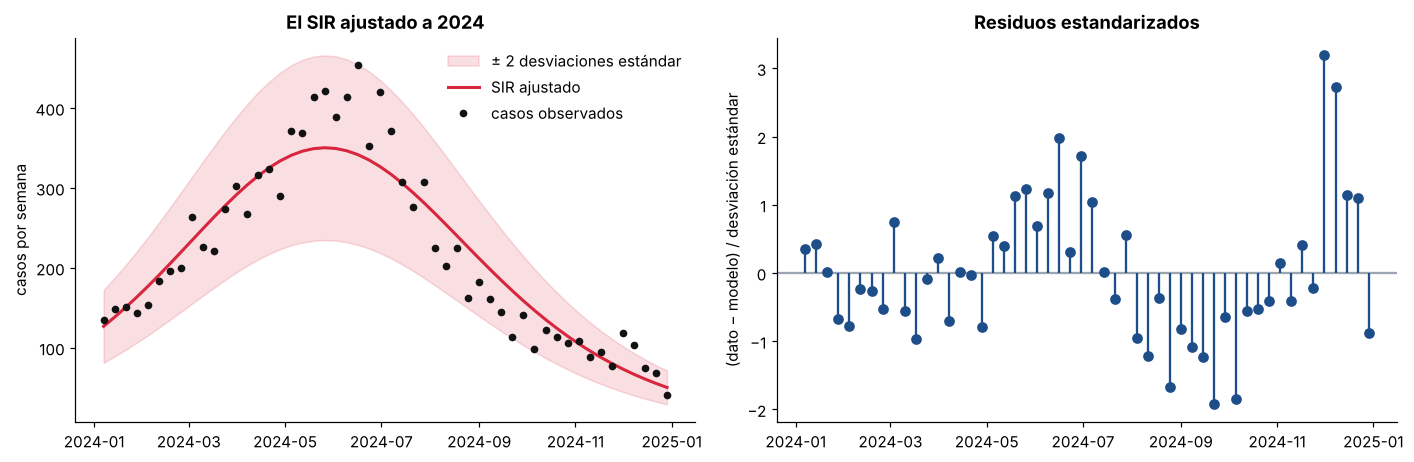

Pico observado: 454 casos | pico del modelo: 350 | semanas fuera de la banda: 2 de 52


In [6]:
libre = ajustar(y)
print("Estimadores de máxima verosimilitud, con los cinco parámetros libres")
print(f"  beta  = {libre['beta']:.3f} por semana")
print(f"  gamma = {libre['gamma']:.3f} por semana   (duración media de la infección: {1 / libre['gamma']:.2f} semanas)")
print(f"  R0    = {libre['R0']:.3f}")
print(f"  r     = {libre['r']:.4f} por semana       (los casos se duplican cada {np.log(2) / libre['r']:.1f} semanas al comienzo)")
print(f"  N     = {libre['N']:,.0f} personas          (población efectiva)".replace(",", "."))
print(f"  I0    = {libre['I0']:.0f} infectados en la primera semana")
print(f"  k     = {libre['k']:.1f}")
print(f"  log-verosimilitud máxima = {libre['logver']:.2f}")

mu = libre["mu"]; desviacion = np.sqrt(mu + mu**2 / libre["k"])
fig, (izq, der) = plt.subplots(1, 2, figsize=(13, 4.3))
izq.fill_between(ola.index, mu - 2 * desviacion, mu + 2 * desviacion, color="#D7263D", alpha=0.15, label="± 2 desviaciones estándar")
izq.plot(ola.index, mu, color="#D7263D", lw=2, label="SIR ajustado")
izq.plot(ola.index, y, "o", color="#121212", ms=4, label="casos observados")
izq.set(title="El SIR ajustado a 2024", ylabel="casos por semana"); izq.legend(frameon=False)
der.axhline(0, color="#9AA5B1"); der.stem(ola.index, (y - mu) / desviacion, linefmt="#1D4E89", markerfmt="o", basefmt=" ")
der.set(title="Residuos estandarizados", ylabel="(dato − modelo) / desviación estándar"); plt.tight_layout(); plt.show()
print(f"Pico observado: {int(y.max())} casos | pico del modelo: {mu.max():.0f} | semanas fuera de la banda: {int((np.abs(y - mu) > 2 * desviacion).sum())} de {len(y)}")

La curva recoge la forma general y deja ver sus límites. El pico del modelo queda por debajo del observado, y los residuos no se reparten al azar: vienen en rachas del mismo signo. Un SIR tiene una sola joroba simétrica alrededor del pico, y esta epidemia subió despacio y cayó rápido. La racha de residuos es la huella de lo que el modelo no tiene, como el mosquito, la lluvia o los serotipos.

Hay un problema más serio, y no se ve en la gráfica. El optimizador devolvió una duración de la infección de casi una semana justa, y una semana es el valor desde el que lo puse a arrancar. Un optimizador que no se mueve de su punto de partida está diciendo que, en esa dirección, la función es casi plana.

## 5. ¿Se puede estimar $R_0$?

Para averiguarlo fijo la duración de la infección, $1/\gamma$, en un valor, y vuelvo a maximizar la verosimilitud sobre los otros cuatro parámetros. Repito para dieciocho duraciones, de un cuarto de semana a cuarenta semanas. La curva que resulta se llama **verosimilitud perfilada**:

$$\ell_p(\gamma)=\max_{\beta,\,N,\,I_0,\,k}\ \ell(\beta,\gamma,N,I_0,k).$$

La regla habitual dice que los valores de $\gamma$ a menos de $1{,}92$ unidades de la cima forman un intervalo de confianza de 95 %.

,R0,r,N,log-verosimilitud,pico del modelo
duración (semanas),,,,,
0.25,1.022,0.0870,251925.0,-257.71,348.0
0.50,1.044,0.0890,128224.0,-257.47,349.0
0.75,1.068,0.0910,87091.0,-257.23,350.0
1.00,1.093,0.0929,66599.0,-256.98,350.0
1.50,1.145,0.0966,46252.0,-256.48,352.0
2.00,1.200,0.1000,36223.0,-255.99,353.0
2.50,1.258,0.1031,30315.0,-255.52,355.0
3.00,1.318,0.1059,26463.0,-255.06,356.0
4.00,1.443,0.1107,21828.0,-254.25,359.0


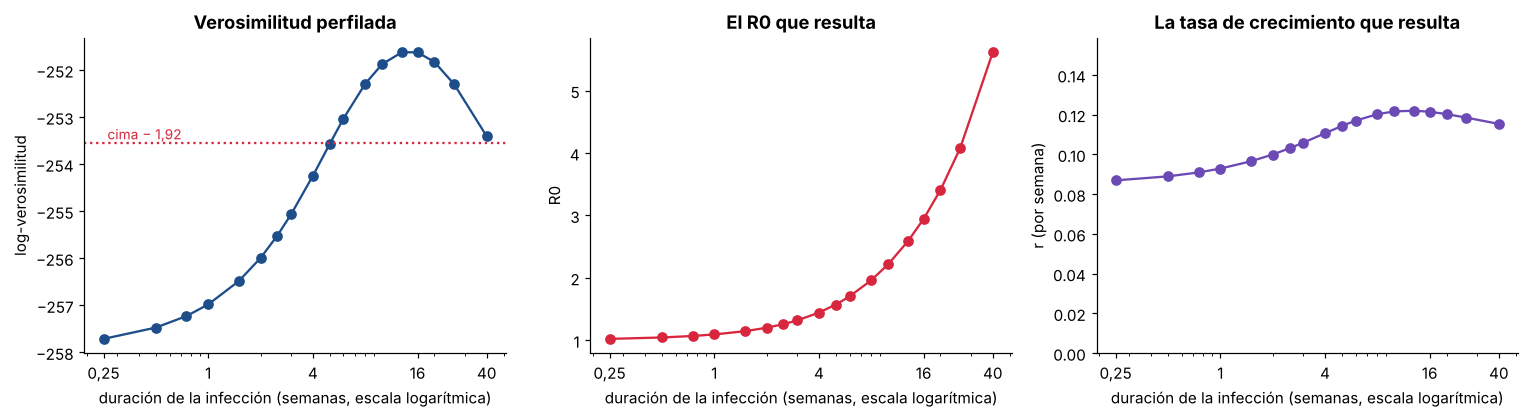

La cima está en una duración de 13 semanas, con R0 = 2.59 y log-verosimilitud -251.62.
El primer ajuste, el que se quedó en una semana, tenía log-verosimilitud -256.98: 5.4 unidades por debajo.
Intervalo de 95 % para la duración: de 6 a 40 semanas. En ese intervalo, R0 va de 1.70 a 5.62.
En el mismo intervalo, r va de 0.115 a 0.122 por semana, y el pico del modelo de 359 a 367 casos.
De un extremo al otro de la rejilla, R0 se multiplica por 5.5 y la log-verosimilitud cambia 6.1 unidades.


In [7]:
duraciones = np.array([0.25, 0.5, 0.75, 1, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10, 13, 16, 20, 26, 40])
perfil, anterior = [], None
for d in duraciones:
    a = ajustar(y, gamma=1 / d, inicio=anterior); anterior = a["p"]
    perfil.append({"duración (semanas)": d, "R0": a["R0"], "r": a["r"], "N": a["N"], "log-verosimilitud": a["logver"], "pico del modelo": a["mu"].max()})
perfil = pd.DataFrame(perfil).set_index("duración (semanas)")
display(perfil.round({"R0": 3, "r": 4, "N": 0, "log-verosimilitud": 2, "pico del modelo": 0}))

cima = perfil["log-verosimilitud"].max(); mejor_duracion = perfil["log-verosimilitud"].idxmax()
dentro = perfil[perfil["log-verosimilitud"] >= cima - 1.92]
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.9))
ejes[0].plot(perfil.index, perfil["log-verosimilitud"], "o-", color="#1D4E89")
ejes[0].axhline(cima - 1.92, color="#D7263D", ls=":"); ejes[0].text(perfil.index[0], cima - 1.92, " cima − 1,92", color="#D7263D", ha="left", va="bottom", fontsize=9)
ejes[0].set(title="Verosimilitud perfilada", ylabel="log-verosimilitud")
ejes[1].plot(perfil.index, perfil["R0"], "o-", color="#D7263D"); ejes[1].set(title="El R0 que resulta", ylabel="R0")
ejes[2].plot(perfil.index, perfil["r"], "o-", color="#6C4AB6"); ejes[2].set(title="La tasa de crecimiento que resulta", ylabel="r (por semana)", ylim=(0, perfil["r"].max() * 1.3))
for eje in ejes:
    eje.set_xscale("log"); eje.set_xticks([0.25, 1, 4, 16, 40]); eje.set_xticklabels(["0,25", "1", "4", "16", "40"]); eje.set_xlabel("duración de la infección (semanas, escala logarítmica)")
plt.tight_layout(); plt.show()
print(f"La cima está en una duración de {mejor_duracion:.0f} semanas, con R0 = {perfil.loc[mejor_duracion, 'R0']:.2f} y log-verosimilitud {cima:.2f}.")
print(f"El primer ajuste, el que se quedó en una semana, tenía log-verosimilitud {libre['logver']:.2f}: {cima - libre['logver']:.1f} unidades por debajo.")
print(f"Intervalo de 95 % para la duración: de {dentro.index.min():.0f} a {dentro.index.max():.0f} semanas. En ese intervalo, R0 va de {dentro['R0'].min():.2f} a {dentro['R0'].max():.2f}.")
print(f"En el mismo intervalo, r va de {dentro['r'].min():.3f} a {dentro['r'].max():.3f} por semana, y el pico del modelo de {dentro['pico del modelo'].min():.0f} a {dentro['pico del modelo'].max():.0f} casos.")
print(f"De un extremo al otro de la rejilla, R0 se multiplica por {perfil['R0'].max() / perfil['R0'].min():.1f} y la log-verosimilitud cambia {cima - perfil['log-verosimilitud'].min():.1f} unidades.")

Hay tres cosas que leer en esta salida.

La primera es sobre el optimizador. El ajuste de la sección 4 no había llegado al máximo. Se quedó en la duración de arranque porque la superficie es tan plana en esa dirección que el algoritmo no encontró razón para moverse. El optimizador siempre devuelve un número, y solo la curva perfilada muestra si ese número es una cima.

La segunda es sobre la duración. La cima existe, pero es muy ancha, y está en un lugar que no tiene sentido biológico: nadie pasa meses infectado de dengue. El modelo usa una infección larga para imitar una epidemia que subió despacio y cayó rápido, que es justo lo que un SIR no sabe hacer. Cuando un parámetro se va a un valor absurdo para mejorar el ajuste, casi siempre está pagando por algo que al modelo le falta.

La tercera es sobre $R_0$. Dentro del intervalo de confianza de la duración, $R_0$ cambia varias veces de tamaño, mientras la tasa de crecimiento $r$ y el pico casi no se mueven. Son curvas distintas en sus parámetros y casi iguales en lo que predicen.

La razón está en las ecuaciones. Mientras casi todos son susceptibles, $I'\approx(\beta-\gamma)\,I$, y lo que la curva muestra es $r=\beta-\gamma$. Hay infinitas parejas $(\beta,\gamma)$ con la misma diferencia. Para verlo en dos dimensiones calculo la verosimilitud perfilada en una rejilla de duración y de tasa de crecimiento, y marco la región que queda a menos de $3{,}0$ unidades del máximo, que para dos parámetros es la región aproximada de confianza de 95 %. La celda resuelve la ecuación diferencial unas cien mil veces y tarda cerca de dos minutos.

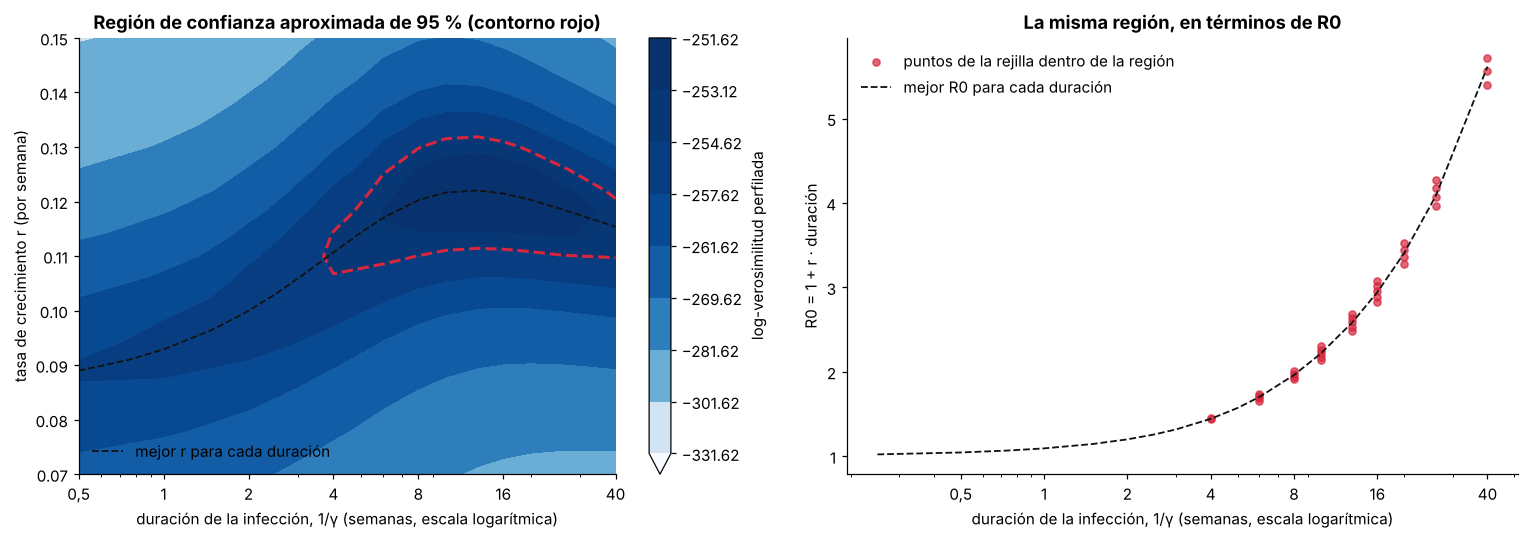

Dentro de la región: r entre 0.110 y 0.130 por semana | duración entre 4 y 40 semanas | R0 entre 1.44 y 5.72


In [8]:
rejilla_d = np.array([0.5, 1, 2, 3, 4, 6, 8, 10, 13, 16, 20, 26, 40])
rejilla_r = np.linspace(0.070, 0.150, 21)
superficie = np.full((len(rejilla_r), len(rejilla_d)), np.nan)
for j, d in enumerate(rejilla_d):
    anterior = None
    for i in np.argsort(np.abs(rejilla_r - np.interp(d, perfil.index, perfil["r"]))):      # se empieza cerca del máximo de esa columna
        a = ajustar(y, gamma=1 / d, R0=1 + rejilla_r[i] * d, inicio=anterior)                 # R0 = 1 + r · duración
        superficie[i, j] = a["logver"]
        if anterior is None: anterior = a["p"]

fig, (izq, der) = plt.subplots(1, 2, figsize=(14, 5))
niveles = cima - np.array([80, 50, 30, 18, 10, 6, 3, 1.5, 0])
mapa = izq.contourf(rejilla_d, rejilla_r, superficie, levels=niveles, cmap="Blues", extend="min")
fig.colorbar(mapa, ax=izq, label="log-verosimilitud perfilada")
izq.contour(rejilla_d, rejilla_r, superficie, levels=[cima - 3.0], colors="#D7263D", linewidths=2)
izq.plot(perfil.index[perfil.index >= 0.5], perfil["r"][perfil.index >= 0.5], "--", color="#121212", lw=1.2, label="mejor r para cada duración")
izq.set(xscale="log", xlabel="duración de la infección, 1/γ (semanas, escala logarítmica)", ylabel="tasa de crecimiento r (por semana)", title="Región de confianza aproximada de 95 % (contorno rojo)")
izq.set_xticks([0.5, 1, 2, 4, 8, 16, 40]); izq.set_xticklabels(["0,5", "1", "2", "4", "8", "16", "40"]); izq.legend(frameon=False, loc="lower left")

en_region = superficie >= cima - 3.0
D, R = np.meshgrid(rejilla_d, rejilla_r)
der.scatter(D[en_region], 1 + R[en_region] * D[en_region], s=22, color="#D7263D", alpha=0.7, label="puntos de la rejilla dentro de la región")
der.plot(perfil.index, perfil["R0"], "--", color="#121212", lw=1.2, label="mejor R0 para cada duración")
der.set(xscale="log", xlabel="duración de la infección, 1/γ (semanas, escala logarítmica)", ylabel="R0 = 1 + r · duración", title="La misma región, en términos de R0")
der.set_xticks([0.5, 1, 2, 4, 8, 16, 40]); der.set_xticklabels(["0,5", "1", "2", "4", "8", "16", "40"]); der.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()
print(f"Dentro de la región: r entre {R[en_region].min():.3f} y {R[en_region].max():.3f} por semana | duración entre {D[en_region].min():.0f} y {D[en_region].max():.0f} semanas | R0 entre {(1 + R * D)[en_region].min():.2f} y {(1 + R * D)[en_region].max():.2f}")

En el panel de la izquierda la región de confianza es una franja horizontal. Es angosta en la tasa de crecimiento y muy larga en la duración. En el de la derecha se ve lo que eso le hace a $R_0=1+r/\gamma$: recorre toda la franja de abajo arriba.

En estadística esto se llama un problema de **identificabilidad**. La respuesta a la pregunta 2 es que la curva de casos estima bien la tasa de crecimiento y estima muy mal $R_0$, y que el valor de $R_0$ en la cima depende de una duración que no es creíble.

## 6. Traer de afuera lo que la curva no tiene

La recta se corta con un dato que no viene de la serie. En un SIR, $1/\gamma$ es el tiempo medio entre una infección y las que esa infección produce. Para el dengue ese intervalo se ha medido: un estudio con pacientes hospitalizados en Tailandia encontró que lo más probable es que pasen entre 15 y 17 días entre dos casos sucesivos de la cadena de transmisión ([Aldstadt y colaboradores, 2012](https://doi.org/10.1111/j.1365-3156.2012.03040.x)). Fijo la duración en 16 días y vuelvo a perfilar, ahora sobre $R_0$, con la regla de $1{,}92$ para el intervalo.

Duración de 15 días: R0 = 1.216 | r = 0.1009 por semana | N efectiva = 34.240 | log-verosimilitud = -255.85
Duración de 16 días: R0 = 1.233 | r = 0.1018 por semana | N efectiva = 32.516 | log-verosimilitud = -255.72
Duración de 17 días: R0 = 1.249 | r = 0.1027 por semana | N efectiva = 31.003 | log-verosimilitud = -255.58

Con 16 días: R0 = 1.23, intervalo de 95 % de 1.21 a 1.25
Los casos se duplicaban cada 6.8 semanas al comienzo de 2024.
Costo de fijar la duración en 16 días: 4.1 unidades de log-verosimilitud por debajo de la cima.


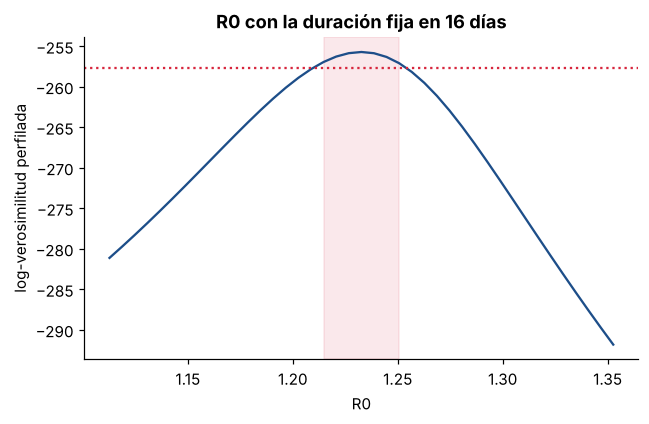

In [9]:
def intervalo_R0(y, dias, centro):
    """Estimador de R0 con la duración fija en `dias`, e intervalo de 95 % por verosimilitud perfilada."""
    g = 7 / dias
    R0s = np.linspace(max(1.001, centro["R0"] - 0.12), centro["R0"] + 0.12, 41)
    logver = np.array([ajustar(y, gamma=g, R0=R, inicio=centro["p"])["logver"] for R in R0s])
    dentro = R0s[logver >= centro["logver"] - 1.92]
    return dentro.min(), dentro.max(), R0s, logver

externo = {dias: ajustar(y, gamma=7 / dias) for dias in (15, 16, 17)}
bajo, alto, R0s, curva = intervalo_R0(y, 16, externo[16])
for dias, a in externo.items():
    print(f"Duración de {dias} días: R0 = {a['R0']:.3f} | r = {a['r']:.4f} por semana | N efectiva = {a['N']:,.0f} | log-verosimilitud = {a['logver']:.2f}".replace(",", "."))
print(f"\nCon 16 días: R0 = {externo[16]['R0']:.2f}, intervalo de 95 % de {bajo:.2f} a {alto:.2f}")
print(f"Los casos se duplicaban cada {np.log(2) / externo[16]['r']:.1f} semanas al comienzo de 2024.")
print(f"Costo de fijar la duración en 16 días: {cima - externo[16]['logver']:.1f} unidades de log-verosimilitud por debajo de la cima.")

plt.figure(figsize=(6.5, 3.8))
plt.plot(R0s, curva, color="#1D4E89"); plt.axhline(externo[16]["logver"] - 1.92, color="#D7263D", ls=":")
plt.axvspan(bajo, alto, color="#D7263D", alpha=0.10); plt.xlabel("R0"); plt.ylabel("log-verosimilitud perfilada"); plt.title("R0 con la duración fija en 16 días"); plt.show()

Con la duración fija, la verosimilitud de $R_0$ sí tiene una cima angosta. El intervalo es estrecho porque toda la incertidumbre sobre la duración quedó por fuera: mover el supuesto de 15 a 17 días cambia $R_0$ más o menos lo mismo que el ancho del intervalo.

Hay una tensión que no quiero esconder. Con la duración en 16 días, el modelo ajusta peor que en su cima, y la diferencia supera las $1{,}92$ unidades de la regla. Este SIR y este dato, juntos, rechazan la duración que mide la literatura. Entre un intervalo medido con pacientes y un parámetro que se fue a un valor absurdo para compensar lo que al modelo le falta, le creo al primero. La tensión habla del modelo.

Tres salvedades para leer ese número.

- Es el número reproductivo **del modelo**, al comienzo de la ventana y dentro de su población efectiva. No distingue serotipos ni inmunidad previa, y en una ciudad donde el dengue circula todos los años se parece más a un número reproductivo efectivo que a un $R_0$ de manual.
- El intervalo de 15 a 17 días viene de otro país y de otro año. Con el mosquito a otra temperatura, ese tiempo cambia.
- La ventana es una decisión mía. La celda siguiente la mueve.

In [10]:
ventanas = {"2024, de enero a diciembre": ("2024-01-07", "2024-12-29"),
            "Desde octubre de 2023 hasta agosto de 2025": ("2023-10-01", "2025-08-10"),
            "Desde enero de 2023 hasta agosto de 2025": ("2023-01-01", "2025-08-10"),
            "La epidemia anterior: enero de 2019 a junio de 2020": ("2019-01-06", "2020-06-28")}
filas = {}
for nombre, (desde, hasta) in ventanas.items():
    tramo = serie[desde:hasta].values.astype(float)
    a = ajustar(tramo, gamma=7 / 16)
    filas[nombre] = {"semanas": len(tramo), "casos": int(tramo.sum()), "R0 (duración de 16 días)": a["R0"], "r por semana": a["r"],
                     "pico observado": int(tramo.max()), "pico del modelo": a["mu"].max()}
sensibilidad = pd.DataFrame(filas).T
display(sensibilidad.round({"R0 (duración de 16 días)": 2, "r por semana": 3, "pico del modelo": 0}))

,semanas,casos,R0 (duración de 16 días),r por semana,pico observado,pico del modelo
"2024, de enero a diciembre",52.0,11437.0,1.23,0.102,454.0,354.0
Desde octubre de 2023 hasta agosto de 2025,98.0,15337.0,1.10,0.043,454.0,240.0
Desde enero de 2023 hasta agosto de 2025,137.0,17595.0,1.13,0.055,454.0,250.0
La epidemia anterior: enero de 2019 a junio de 2020,78.0,3530.0,1.15,0.067,112.0,73.0


La ventana mueve el resultado más que el supuesto sobre la duración. Cuando la ventana incluye 2023, el modelo tiene que explicar con una sola joroba un año de meseta y otro de epidemia, el pico le queda mucho más bajo que el observado y la tasa de crecimiento sale menor. El número reproductivo depende de qué tramo se le pida explicar, y por eso hay que reportarlo con su ventana.

## 7. ¿Y sirve para pronosticar?

Esta es la pregunta del post. Puse a competir al SIR contra los modelos del taller en la misma tarea: pronosticar los casos a 1, 2, 4 y 8 semanas, cada semana, con lo conocido hasta ese día. El SIR se reajusta cada semana con las últimas 16. La competencia completa tarda cerca de un cuarto de hora, así que aquí leo las predicciones ya guardadas. El código que las produce está en `herramientas/posts/dengue/` del repositorio.

In [11]:
pred = pd.read_csv(raiz / "documentos" / "posts" / "dengue" / "pred_prueba.csv.gz", parse_dates=["origen", "fecha"])
pred["error"] = (pred["pred"] - pred["real"]).abs()
nombres = {"SIR (ventana 16, gamma libre)": "SIR reajustado cada semana", "ingenuo": "igual que la última semana", "ridge (cambio)": "regresión ridge con rezagos",
           "bosque (cambio)": "bosque aleatorio", "boosting (cambio)": "boosting"}
tabla = pred[pred["modelo"].isin(nombres)].assign(modelo=lambda t: t["modelo"].map(nombres)).pivot_table(index="modelo", columns="h", values="error").loc[list(nombres.values())]
tabla.columns = [f"{h} semana" + ("s" if h > 1 else "") for h in tabla.columns]
print(f"Error absoluto medio, en casos por semana. Prueba: {pred['fecha'].min().date()} a {pred['fecha'].max().date()}, {pred[pred['h'] == 1]['fecha'].nunique()} semanas.")
display(tabla.round(1))

gamma_fija = pred[pred["modelo"].str.startswith("SIR (ventana 16")].pivot_table(index="modelo", columns="h", values="error")
print("\nEl mismo SIR con la duración fija en una semana, en dos, o libre:"); display(gamma_fija.round(1))

Error absoluto medio, en casos por semana. Prueba: 2023-01-01 a 2025-08-10, 137 semanas.


,1 semana,2 semanas,4 semanas,8 semanas
modelo,,,,
SIR reajustado cada semana,17.2,19.6,29.4,53.2
igual que la última semana,18.2,21.2,30.4,51.3
regresión ridge con rezagos,18.2,22.8,34.1,50.7
bosque aleatorio,18.2,21.0,31.5,58.8
boosting,18.7,21.5,33.1,65.7



El mismo SIR con la duración fija en una semana, en dos, o libre:


h,1,2,4,8
modelo,,,,
"SIR (ventana 16, 1/gamma = 1 sem)",17.2,19.5,29.3,53.2
"SIR (ventana 16, 1/gamma = 2 sem)",17.2,19.5,29.2,52.9
"SIR (ventana 16, gamma libre)",17.2,19.6,29.4,53.2


Nadie le gana con claridad a repetir el último dato. El SIR queda adelante por uno o dos casos a 1, 2 y 4 semanas, y esa ventaja cabe dentro del margen de azar. A 8 semanas pierde.

La segunda tabla cierra el argumento de la sección 5 por otro camino. El SIR pronostica igual con la duración en una semana, en dos o libre. Para pronosticar a pocas semanas basta la tasa de crecimiento, que es lo que el dato sí tiene, y $R_0$ no hace falta.

## Lo que queda

1. Con Runge-Kutta y una verosimilitud se puede ajustar un modelo mecanicista a un dato público en un cuaderno. El modelo describe la forma general de la epidemia de 2024 y falla en el pico.
2. La curva de casos estima bien la tasa de crecimiento y muy mal $R_0$. El optimizador siempre devuelve un número, y la verosimilitud perfilada es la que dice si ese número es una cima y si la cima está en un lugar creíble.
3. Con un intervalo entre casos traído de la literatura, $R_0$ queda estimado con un intervalo estrecho, que no incluye la incertidumbre de ese supuesto ni la de la ventana. El modelo, dejado solo, prefiere una duración que la biología no admite.
4. Para pronosticar a pocas semanas, el modelo de matemática aplicada y los de aprendizaje automático empatan con la regla más simple.

## Límites

- El modelo no tiene mosquito, clima, serotipos ni inmunidad previa.
- Una ficha existe solo si la persona consultó y el médico notificó. La población efectiva $N$ absorbe ese subregistro, y por eso no se puede leer como población de la ciudad.
- Usé la serie ya consolidada. En tiempo real, las últimas semanas llegan incompletas.
- Los intervalos salen de la verosimilitud perfilada con su aproximación habitual, y suponen que el modelo es correcto. Los residuos de la sección 4 dicen que no lo es del todo.